In [ ]:
from typing import Annotated

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from langchain_tavily import TavilySearch
import inspect
import json
from pprint import pprint
from langgraph.types import Command, interrupt
from langchain_core.tools import tool

In [3]:

def display_graph(graph:StateGraph)->None:
    display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
tavily_tool=TavilySearch(max_results=2)

In [5]:
load_dotenv()

llm = ChatOpenAI(model="gpt-5-nano")

In [30]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assitance(query: str)-> str:
    """Request assitance for a human."""
    print('I am here')
    human_response = interrupt({"query":query})
    print("after humam response")
    return human_response["data"]

tools = [tavily_tool, human_assitance]
llm_with_tools = llm.bind_tools(tools)

def chatbot(state: State):
    print("this is the chatbot node")

    message = llm_with_tools.invoke(state["messages"])

    return {"messages": [message]}

graph_builder.add_node("chatbot", chatbot)

tool_node = ToolNode(tools=tools)

graph_builder.add_node("tools", tool_node)

#automatically adds edges to tools and end nodes
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)

graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")



In [37]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
graph = graph_builder.compile(
    checkpointer=memory
)

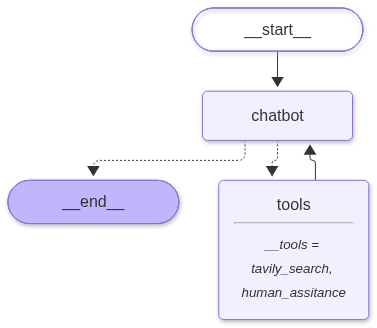

In [38]:
display_graph(graph)

In [42]:
user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me? you can requestn human asistance"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)

for event in events:
    
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me? you can requestn human asistance
this is the chatbot node
================================== Ai Message ==================================
Tool Calls:
  human_assitance (call_Gc9D1B8KltuSzr0uiPA37dKq)
 Call ID: call_Gc9D1B8KltuSzr0uiPA37dKq
  Args:
    query: Request expert guidance and hands-on assistance to design and build a robust AI agent capable of natural language interactions, multi-step task execution, and external-tool integration (APIs). The agent should support memory/context retention, tool use, and safe operation within defined constraints. Seeking AI/ML engineers with experience in building AI agents/autonomous systems, NLP engineers with experience in tool-using agents and memory management, MLOps/software engineers for deployment and reliability, and safety/ethics experts for guardrai

In [43]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume={"data": human_response})

events = graph.stream(human_command, config, stream_mode="values")

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assitance (call_Gc9D1B8KltuSzr0uiPA37dKq)
 Call ID: call_Gc9D1B8KltuSzr0uiPA37dKq
  Args:
    query: Request expert guidance and hands-on assistance to design and build a robust AI agent capable of natural language interactions, multi-step task execution, and external-tool integration (APIs). The agent should support memory/context retention, tool use, and safe operation within defined constraints. Seeking AI/ML engineers with experience in building AI agents/autonomous systems, NLP engineers with experience in tool-using agents and memory management, MLOps/software engineers for deployment and reliability, and safety/ethics experts for guardrails and auditing. Remote collaboration; cloud hosting (AWS/Azure/GCP) or hybrid; security/privacy requirements to be discussed. Deliverables include architecture blueprint, MVP roadmap (4-8 weeks), sample code skeletons and integration patterns fo